# Mini-Challenge 1 – Convolution and Deconvolution
## Day 11 – Data & Domain

### Use Case: Smoothing and Restoration of Strong-Motion Records

After an earthquake in Japan, strong-motion records are used within minutes to estimate shaking intensity and potential damage. Every record passes through a measurement and processing chain (sensor, electronics, digital filters) that acts as a convolution: it smooths the signal to a certain degree.

**Convolution.** Raw acceleration records contain high-frequency fluctuations from local wave scattering and instrument noise on top of the dominant S-wave pulses. For an overview of the shaking relevant to buildings, whose response is concentrated at lower frequencies (≈ 1–5 Hz), these fluctuations are a disturbance. Convolution with a smoothing kernel suppresses them and makes the dominant pulses easier to identify.

**Deconvolution.** Smoothing also reduces peak amplitudes and blurs sharp onsets. The peak ground acceleration (PGA), however, enters directly into intensity and damage estimates; an underestimated PGA underestimates the shaking. If a record is only available in smoothed form, or if the measurement chain itself acts as a smoother, deconvolution aims to recover the original peaks and onsets from the filtered signal.

### Problem Statement

**Convolution.** The acceleration record contains high-frequency components that obscure the dominant S-wave pulses. Convolution with a suitable smoothing kernel should attenuate these components while preserving the main pulses. However, smoothing also lowers peak amplitudes, broadens short pulses and blurs the P-wave onset, which are exactly the features needed for PGA-based assessment.

**Deconvolution.** After filtering, deconvolution is used to investigate to what extent the original peaks and onsets can be recovered from the smoothed signal. The challenge is that frequency components strongly attenuated by the kernel can only be restored by amplifying them, which also amplifies noise and may make the reconstruction unstable; components removed completely are lost and cannot be recovered at all.

Convolution is applied in the time domain, the one-dimensional equivalent of the spatial domain for images: the kernel slides along the time axis and forms a weighted average of neighbouring samples.

### Signal Selection

| Property | Value |
|---|---|
| Physical origin | Ground acceleration from the M4.5 earthquake on 2026-09-26, 10:31 (JST), Kumamoto, 10 km depth |
| Station / component | KMM006 (K-NET), EW (horizontal) |
| Unit | gal (= cm/s²) |
| Acquisition | Accelerometer, digitized at 100 Hz (raw counts × scale factor) |
| Window | 15–25 s (P onset, S-wave packet, early coda) |
| Characteristics | Sharp P onset at ≈ 15.2 s; S-wave pulses with peaks of ≈ −100 gal at ≈ 16.5–17 s; dominant frequencies ≈ 2–4 Hz (S wave) with higher-frequency content in the P wave (≈ 5–10 Hz) |

**Choice of component.** The EW component shows the clearest large S-wave pulses together with a visible P onset. These sharp features are what smoothing affects most, so the effect of convolution and the quality of the restoration become directly visible. Using a third component also complements the UD (sampling) and NS (correlation) analyses.

**Choice of window.** 15–25 s covers the P onset, the strongest pulses and the early coda, i.e. both sharp and smooth parts of the signal. The pre-event noise is excluded, as it contains no features to preserve.

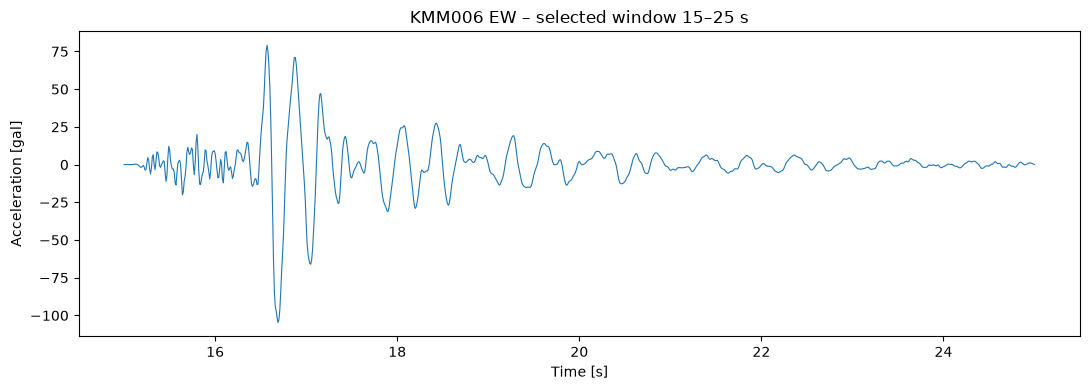

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from src.knet_io import read_knet

FILE = "data/20260926103100/knet/ascii/KMM0062609261031.EW"
T_START, T_END = 15.0, 25.0   # selected window [s]

acc, fs, hdr = read_knet(FILE)
t = np.arange(len(acc)) / fs
mask = (t >= T_START) & (t <= T_END)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t[mask], acc[mask], lw=0.8)
ax.set(xlabel="Time [s]", ylabel="Acceleration [gal]",
       title=f"{hdr['Station Code']} EW – selected window {T_START:.0f}–{T_END:.0f} s")
plt.tight_layout()
plt.show()

### Expected Effects

**Convolution (smoothing).**
- High-frequency fluctuations are attenuated; the dominant S-wave pulses (≈ 2–4 Hz) remain visible.
- Peak amplitudes decrease, as each value is averaged with smaller neighbours; the PGA is therefore underestimated.
- Short pulses become broader and the P-wave onset less sharp.
- The stronger the smoothing (wider kernel), the stronger all of these effects.

**Deconvolution (restoration).**
- If the kernel is known, the smoothing can in principle be inverted, so peaks and onsets should partly return.
- Frequencies that the kernel attenuated strongly can only be restored by amplifying them, which also amplifies any noise in the filtered signal. Without regularization, the reconstruction may become unstable.
- Frequencies that the kernel removed completely cannot be recovered; this part of the information is lost.

The block therefore investigates a trade-off: how much smoothing is useful, and how much of the original signal can be restored afterwards.

### Data Source

National Research Institute for Earth Science and Disaster Resilience (NIED): K-NET, KiK-net. doi:10.17598/NIED.0004

## Day 12 – Methodological Design

### Convolution Kernels

Two kernels are used: a **Gaussian kernel** as the main filter and a **moving-average kernel** with comparable smoothing strength as a comparison. Both are symmetric, so the filtered signal is not shifted in time and pulse and onset times are preserved. Both are normalized to a sum of 1, so the mean of the signal is unchanged and only fluctuations are smoothed.

**Gaussian kernel (main).** Its frequency response is itself a Gaussian, $H(f) = e^{-2\pi^2\sigma^2 f^2}$: it decreases smoothly with frequency, has no zeros and no ripples. High frequencies are attenuated progressively without completely removing any frequency, which keeps the smoothing reversible in principle.

**Moving-average kernel (comparison).** It replaces each sample by the mean of its $L$ neighbours. Its frequency response is a sinc function with zeros at multiples of $f_s / L$: these frequencies are removed completely. The comparison shows how the kernel type, not only its strength, determines what deconvolution can restore.

**Kernel size.** The size is chosen from the frequency content of the signal. The S-wave pulses (≈ 2–4 Hz) are to be preserved, while faster fluctuations (≳ 10 Hz) are to be attenuated. A cutoff frequency of about 6–7 Hz lies between these ranges.
- Gaussian: $f_c \approx 0.13/\sigma$, so **σ = 20 ms** (2 samples) gives $f_c$ ≈ 6.6 Hz. At 3 Hz the gain is still 0.93, at 10 Hz 0.45 and at 20 Hz 0.04. The kernel is truncated at ±3σ (13 samples), where the Gaussian has fallen below 1.2 % of its maximum.
- Moving average: $f_c \approx 0.44\,f_s/L$, so **L = 7 samples** (70 ms) gives $f_c$ ≈ 6.3 Hz, i.e. comparable smoothing. Its first zero lies at $f_s/L$ ≈ 14.3 Hz.

**Parameter.** The kernel width (σ or $L$) is the key parameter: wider kernels suppress more fluctuations but also reduce peaks more strongly and broaden pulses. It will be varied on Day 14.

### Deconvolution Approaches

| Approach | Principle | Strengths | Weaknesses |
|---|---|---|---|
| Inverse filtering | Divides the spectrum of the filtered signal by the kernel response, $X = Y/H$ | Exact without noise; no parameters | Unstable where $H$ is small: noise is amplified enormously; undefined where $H = 0$ |
| Regularized inverse (Tikhonov) | Adds a constant $\lambda$ to the denominator, $X = H^* Y / (\lvert H \rvert^2 + \lambda)$ | Stable; one parameter | $\lambda$ has no direct physical meaning and must be tuned |
| Wiener filtering | Weights each frequency by the expected signal-to-noise ratio, $X = H^* Y / (\lvert H \rvert^2 + K)$ | Minimizes the mean squared error for a known kernel and noise; $K$ is interpretable as the noise-to-signal power ratio | Requires an estimate of the noise level |
| Richardson–Lucy | Iterative, statistically motivated restoration | Well established for images | Assumes non-negative data; acceleration takes positive and negative values |
| Blind deconvolution | Estimates the kernel and the signal jointly | Works with unknown kernels | Ill-posed and more complex; unnecessary, since the kernel is known here |

**Choice: Wiener filtering.** The kernel is known and the filtered record contains noise, which is exactly the situation Wiener filtering is designed for. It is stable, as frequencies with low signal-to-noise ratio are suppressed instead of amplified, and it has a single parameter $K$ with a physical meaning (noise-to-signal power ratio), which can be set from the known noise level. Plain inverse filtering is not suitable: the Gaussian response drops to about $3 \cdot 10^{-6}$ at 40 Hz, so even tiny noise there would be amplified by a factor of ~300 000. For the moving-average kernel it is undefined at the zeros of $H$. Richardson–Lucy is excluded because the signal is not non-negative.

**Noise.** To make the restoration realistic, a small measurement noise is added to the filtered signal. Without noise, a known Gaussian kernel could be inverted almost perfectly, which would not reflect real records.

### Expected Reconstruction Quality

For the use case, the restoration is useful if the **PGA of the restored signal lies within 10 % of the original PGA**. A 10 % amplitude error changes the JMA instrumental intensity by about $2\log_{10}(1.1) \approx 0.08$, a small fraction of one intensity class, so intensity-based assessments remain practically unaffected (same reasoning as the 10 % threshold in the sampling block). In addition, the restoration must remain stable: it must not introduce oscillations larger than the noise level of the record.

**Expectations**
- *Gaussian kernel:* peaks and onsets should be largely restored, as no frequency is removed completely. Accuracy is limited by noise at high frequencies, which the Wiener filter suppresses rather than restores.
- *Moving-average kernel:* the restoration is expected to be less accurate, as the frequencies at the zeros of its response are lost and cannot be recovered.
- *Wiener parameter K:* a small $K$ restores more detail but amplifies more noise; a large $K$ gives a stable but smoother result. The trade-off is examined on Day 14.

## Day 13 – Technical Implementation

The convolution is implemented manually in the time domain (the 1D equivalent of the spatial domain) and verified against library implementations. The filtered signal is then disturbed by a small measurement noise and restored with Wiener deconvolution. Parameters follow the methodological design of Day 12. Evaluation follows on Day 14.

In [13]:
from scipy.ndimage import convolve1d

FILE = "data/20260926103100/knet/ascii/KMM0062609261031.EW"
T0, T1 = 15.0, 25.0

acc_full, fs, hdr = read_knet(FILE)
t_full = np.arange(len(acc_full)) / fs
mask = (t_full >= T0) & (t_full < T1)
t, x = t_full[mask], acc_full[mask]

print(f"fs = {fs:.0f} Hz, {len(x)} samples, PGA (segment) = {np.max(np.abs(x)):.1f} gal")

fs = 100 Hz, 1000 samples, PGA (segment) = 104.8 gal


Gaussian (σ = 20 ms): 13 samples, sum = 1.000000
Moving average (L = 7): 7 samples, sum = 1.000000


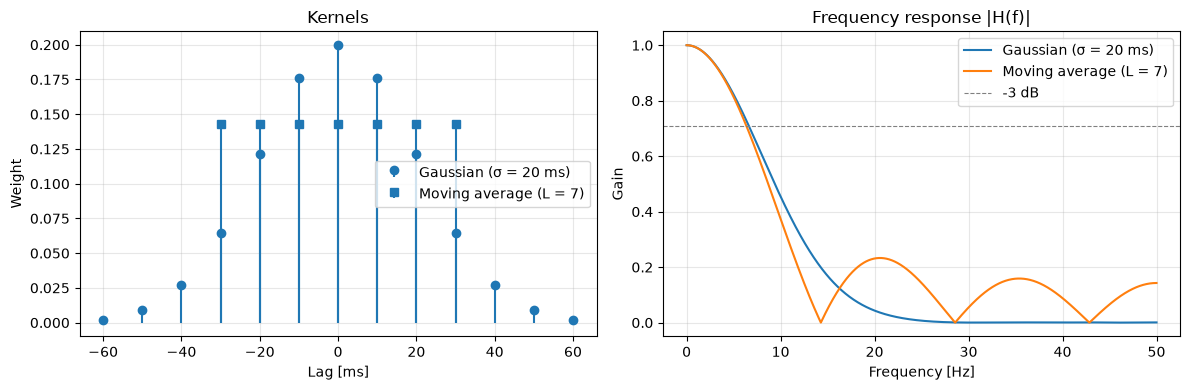

In [14]:
SIGMA_S = 0.020      # Gaussian standard deviation [s]
TRUNCATE = 3.0       # kernel truncated at ±3 sigma
L_MA = 7             # moving-average length [samples]

def gaussian_kernel(sigma_s, fs, truncate=3.0):
    """Normalized, symmetric Gaussian kernel truncated at ±truncate*sigma."""
    sigma = sigma_s * fs                       # sigma in samples
    half = int(np.ceil(truncate * sigma))
    n = np.arange(-half, half + 1)
    h = np.exp(-0.5 * (n / sigma) ** 2)
    return h / h.sum()

def moving_average_kernel(length):
    """Normalized moving-average (box) kernel; length must be odd."""
    return np.ones(length) / length

kernels = {
    f"Gaussian (σ = {SIGMA_S*1000:.0f} ms)": gaussian_kernel(SIGMA_S, fs, TRUNCATE),
    f"Moving average (L = {L_MA})": moving_average_kernel(L_MA),
}
for name, h in kernels.items():
    print(f"{name}: {len(h)} samples, sum = {h.sum():.6f}")

N_FFT = 4096
f_axis = np.fft.rfftfreq(N_FFT, 1 / fs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in kernels.items():
    half = len(h) // 2
    axes[0].stem(np.arange(-half, half + 1) / fs * 1000, h, label=name,
                 markerfmt="o" if "Gauss" in name else "s", basefmt=" ")
    axes[1].plot(f_axis, np.abs(np.fft.rfft(h, N_FFT)), label=name)
axes[0].set(title="Kernels", xlabel="Lag [ms]", ylabel="Weight")
axes[1].axhline(1 / np.sqrt(2), color="gray", ls="--", lw=0.8, label="-3 dB")
axes[1].set(title="Frequency response |H(f)|", xlabel="Frequency [Hz]", ylabel="Gain")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [15]:
def convolve_manual(x, h, boundary="reflect"):
    """1D convolution in the time domain with output length = input length.

    boundary: "reflect" mirrors the signal at its edges (edge sample not repeated),
              "zero" pads with zeros.
    """
    M = len(h)
    if M % 2 == 0:
        raise ValueError("Kernel length must be odd (centered kernel).")
    half = M // 2

    # 1) Boundary handling: extend the signal by half a kernel on each side
    if boundary == "reflect":
        x_pad = np.pad(x, half, mode="reflect")
    elif boundary == "zero":
        x_pad = np.pad(x, half, mode="constant")
    else:
        raise ValueError(f"Unknown boundary mode: {boundary}")

    # 2) Convolution flips the kernel (irrelevant for symmetric kernels, but correct in general)
    h_flipped = h[::-1]

    # 3) Sliding window: multiply window and kernel sample by sample, then sum
    y = np.zeros(len(x))
    for n in range(len(x)):
        window = x_pad[n:n + M]
        y[n] = np.sum(window * h_flipped)
    return y

In [16]:
h_test = np.array([0.1, 0.2, 0.7])   # asymmetric kernel: checks that the flip is correct

rows = []
for name, h in {**kernels, "Asymmetric test kernel": h_test}.items():
    diff_zero = np.max(np.abs(convolve_manual(x, h, "zero") - np.convolve(x, h, mode="same")))
    diff_refl = np.max(np.abs(convolve_manual(x, h, "reflect") - convolve1d(x, h, mode="mirror")))
    diff_bnd = np.abs(convolve_manual(x, h, "zero") - convolve_manual(x, h, "reflect"))
    n_affected = np.sum(diff_bnd > 1e-9)
    rows.append((name, diff_zero, diff_refl, n_affected, diff_bnd.max()))

print(f"{'Kernel':<28}{'zero vs np.convolve':>22}{'reflect vs ndimage':>22}"
      f"{'samples zero≠reflect':>24}{'max diff [gal]':>16}")
for name, dz, dr, na, md in rows:
    print(f"{name:<28}{dz:>22.2e}{dr:>22.2e}{na:>24d}{md:>16.2f}")

Kernel                         zero vs np.convolve    reflect vs ndimage    samples zero≠reflect  max diff [gal]
Gaussian (σ = 20 ms)                      1.42e-14              1.42e-14                      12            0.31
Moving average (L = 7)                    0.00e+00              2.84e-14                       6            0.35
Asymmetric test kernel                    0.00e+00              1.42e-14                       2            0.06


**Verification.** For both boundary modes, the manual convolution matches the library implementations (`np.convolve` with zero padding, `scipy.ndimage.convolve1d` with mirror padding) up to a maximum absolute difference of about 3e-14 gal. This is floating-point rounding, caused by a different summation order, and is far below the measurement resolution. The asymmetric test kernel confirms that the kernel is flipped correctly. Note that NumPy's `reflect` corresponds to SciPy's `mirror` (edge sample not repeated). With mismatched names, the results would differ at the edges.

The two boundary modes differ only in the first and last 6 samples for the Gaussian and 3 samples for the moving average (max. 0.35 gal). Mirror padding is used because the segment starts and ends during strong shaking: zero padding would artificially pull the filtered signal toward zero at the edges.

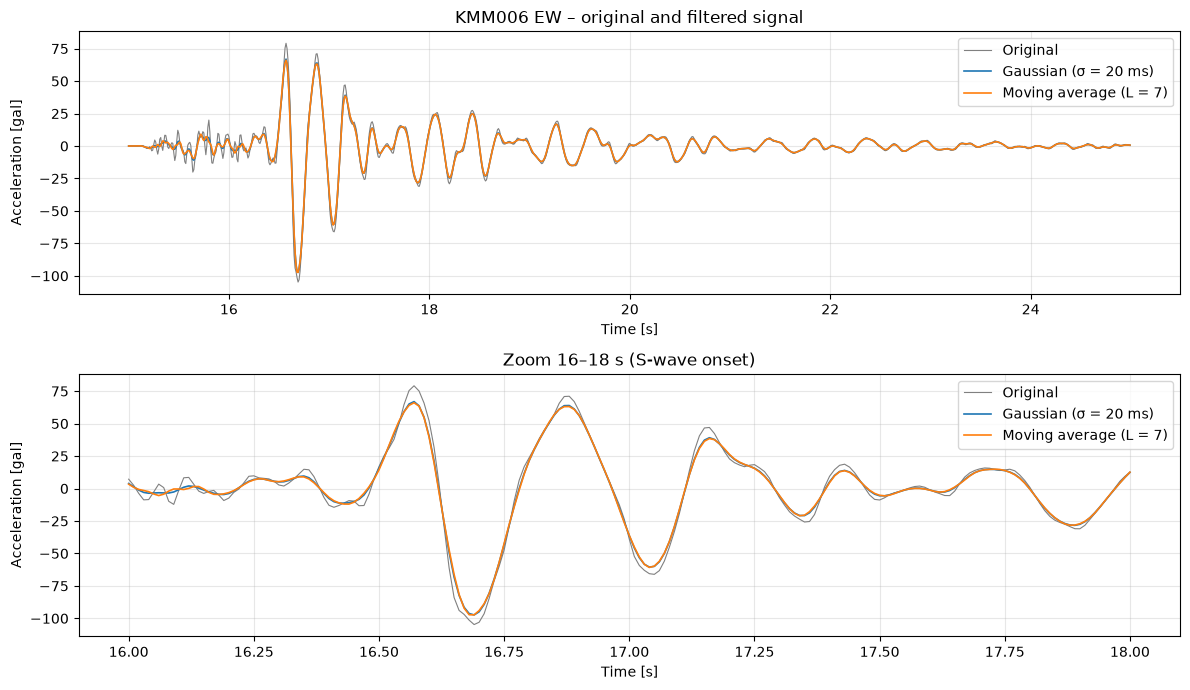

In [17]:
filtered = {name: convolve_manual(x, h, "reflect") for name, h in kernels.items()}

ZOOM = (16.0, 18.0)
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, (t_lo, t_hi) in zip(axes, [(T0, T1), ZOOM]):
    m = (t >= t_lo) & (t <= t_hi)
    ax.plot(t[m], x[m], color="gray", lw=0.8, label="Original")
    for name, y in filtered.items():
        ax.plot(t[m], y[m], lw=1.2, label=name)
    ax.set(xlabel="Time [s]", ylabel="Acceleration [gal]")
    ax.grid(alpha=0.3); ax.legend(loc="upper right")
axes[0].set_title("KMM006 EW – original and filtered signal")
axes[1].set_title(f"Zoom {ZOOM[0]:.0f}–{ZOOM[1]:.0f} s (S-wave onset)")
plt.tight_layout(); plt.show()

In [18]:
SNR_DB = 30                       # measurement noise relative to the filtered signal
K_WIENER = 10 ** (-SNR_DB / 10)   # noise-to-signal power ratio -> 1e-3
rng = np.random.default_rng(42)
noise_unit = rng.standard_normal(len(x))   # same noise realization for both kernels

def wiener_deconvolve(y, h, K, pad=None):
    """Wiener deconvolution X = conj(H) Y / (|H|^2 + K) via FFT.

    The signal is mirror-padded before the FFT to reduce artefacts from the
    circular (periodic) assumption of the DFT; K = 0 gives the naive inverse filter.
    """
    half = len(h) // 2
    pad = pad or 4 * len(h)
    y_pad = np.pad(y, pad, mode="reflect")
    N = len(y_pad)

    # Kernel zero-padded to N samples, centre moved to index 0 (no time shift)
    h_circ = np.zeros(N)
    h_circ[:len(h)] = h
    h_circ = np.roll(h_circ, -half)

    H = np.fft.rfft(h_circ)
    Y = np.fft.rfft(y_pad)
    X = np.conj(H) * Y / (np.abs(H) ** 2 + K)
    return np.fft.irfft(X, n=N)[pad:pad + len(y)]

noisy, restored = {}, {}
for name, h in kernels.items():
    y = filtered[name]
    sigma_noise = np.sqrt(np.mean(y ** 2) * 10 ** (-SNR_DB / 10))
    noisy[name] = y + sigma_noise * noise_unit
    restored[name] = wiener_deconvolve(noisy[name], h, K_WIENER)
    print(f"{name}: noise σ = {sigma_noise:.2f} gal")

# Demonstration: naive inverse filter (K = 0) on the Gaussian
name_g = list(kernels)[0]
naive = wiener_deconvolve(noisy[name_g], kernels[name_g], K=0.0)
print(f"Naive inverse ({name_g}): max |x| = {np.max(np.abs(naive)):.2e} gal")

Gaussian (σ = 20 ms): noise σ = 0.47 gal
Moving average (L = 7): noise σ = 0.47 gal
Naive inverse (Gaussian (σ = 20 ms)): max |x| = 6.81e+03 gal


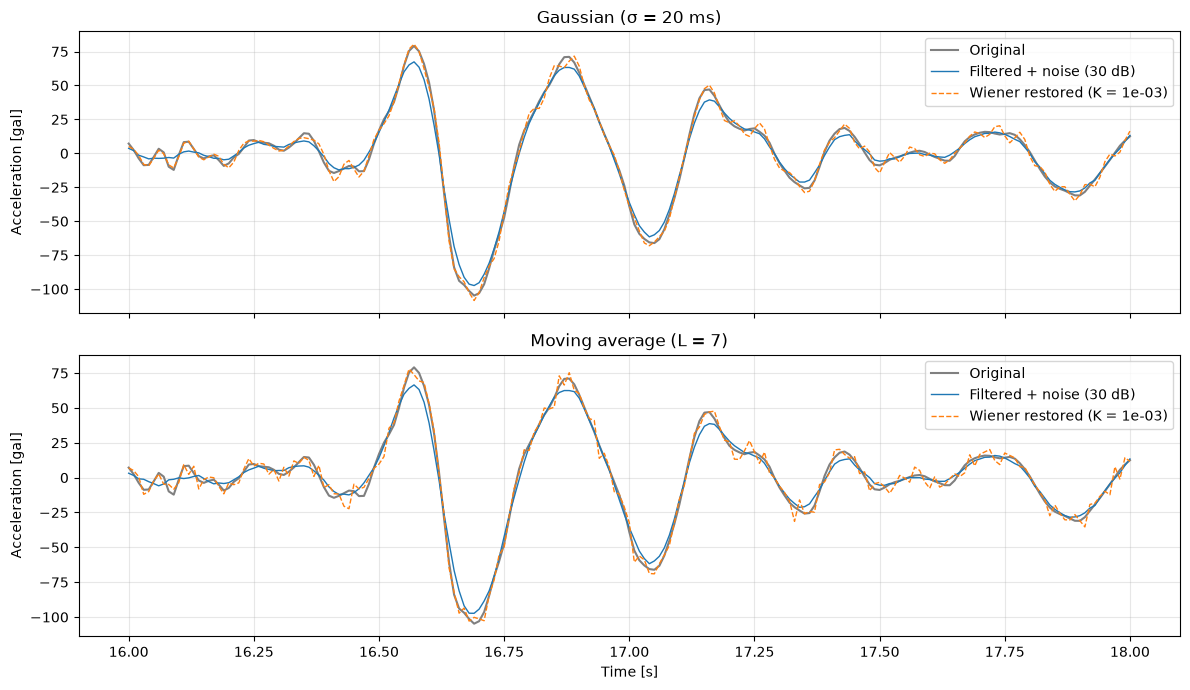

In [19]:
fig, axes = plt.subplots(len(kernels), 1, figsize=(12, 7), sharex=True)
m = (t >= ZOOM[0]) & (t <= ZOOM[1])
for ax, name in zip(axes, kernels):
    ax.plot(t[m], x[m], color="gray", lw=1.5, label="Original")
    ax.plot(t[m], noisy[name][m], lw=1, label=f"Filtered + noise ({SNR_DB} dB)")
    ax.plot(t[m], restored[name][m], lw=1, ls="--", label=f"Wiener restored (K = {K_WIENER:.0e})")
    ax.set(title=name, ylabel="Acceleration [gal]")
    ax.grid(alpha=0.3); ax.legend(loc="upper right")
axes[-1].set_xlabel("Time [s]")
plt.tight_layout(); plt.show()

At the chosen sizes, both kernels produce nearly identical filtered and restored signals, as they were designed with the same cutoff frequency (≈ 6.5 Hz) and the signal energy is concentrated below this frequency. The kernels differ only above ≈ 10 Hz, where the moving average has spectral zeros and side lobes. At 30 dB SNR, the Wiener filter suppresses this range for both kernels, so the information lost at the zeros barely affects the result. It shows only as slightly stronger high-frequency ripples in the moving-average restoration. The difference is expected to grow for larger kernels, whose zeros move into the signal band

**Deconvolution parameters.** Wiener deconvolution is implemented in a few lines with NumPy's FFT, since SciPy provides no one-dimensional Wiener deconvolution (`scipy.signal.wiener` is a denoising filter). The kernel is the same as in the convolution, so the restoration assumes a perfectly known kernel. The regularization parameter $K$ represents the noise-to-signal power ratio. Since the noise was added at 30 dB SNR, $K = 10^{-30/10} = 10^{-3}$. This assumes a flat ratio across all frequencies, which is a simplification: the earthquake signal carries little power at high frequencies, so the true ratio is larger there. The influence of $K$ is therefore examined on Day 14.

Before the FFT, the signal is mirror-padded, consistent with the boundary handling of the convolution, so that the periodic assumption of the DFT does not create artefacts at the segment edges.

**Naive inverse filtering.** For comparison, $K = 0$ was applied to the Gaussian-filtered signal. The result reaches values of about 6.8·10³ gal, i.e. the noise at high frequencies, where $|H|$ is tiny, is amplified by many orders of magnitude. This confirms the choice of a regularized method from Day 12.

## Day 14 – Evaluation

**Evaluation approach.** Filtering and restoration are evaluated with the **signed relative PGA error**

$$e_{\mathrm{PGA}} = \frac{\max|\hat{x}| - \max|x|}{\max|x|} \cdot 100\ \%,$$

where $x$ is the original and $\hat{x}$ the filtered or restored signal. The PGA is the key quantity of the use case (intensity assessment, Day 11). The requirement from Day 12 is $|e_{\mathrm{PGA}}| \le 10\ \%$. The sign separates the two failure modes. A negative error indicates **amplitude loss** from smoothing; a positive error indicates **noise amplification or overshoot** from the restoration. To quantify **stability**, the error is computed for 20 independent noise realizations (30 dB SNR, the same realizations for all configurations) and reported as mean ± standard deviation. The first and last 0.2 s of the segment are excluded to remove boundary artefacts.

**Baseline.** Gaussian kernel σ = 20 ms, Wiener parameter $K = 10^{-3}$, SNR = 30 dB.

**Varied parameters.**
- **A – kernel width:** σ = 10, 20, 30, 40, 60 ms. The moving average uses the odd length $L$ with the same −3 dB cutoff frequency.
- **B – Wiener parameter:** $K = 10^{-6}, \dots, 10^{0}$ at baseline width.

In [20]:
EDGE_S = 0.2           # excluded at both ends [s]
N_TRIALS = 20          # noise realizations per configuration
THRESHOLD_PCT = 10     # requirement from Day 12 [%]

BASELINE_SIGMA_S = 0.020
BASELINE_K = 1e-3

SIGMAS_S = [0.010, 0.020, 0.030, 0.040, 0.060]
K_VALUES = np.logspace(-6, 0, 7)

inner = (t >= T0 + EDGE_S) & (t < T1 - EDGE_S)
pga_true = np.max(np.abs(x[inner]))

def pga_error(sig):
    """Signed relative PGA error [%] with respect to the original segment (edges excluded)."""
    return 100 * (np.max(np.abs(sig[inner])) - pga_true) / pga_true

def matched_ma_length(sigma_s, fs):
    """Odd moving-average length with the same -3 dB cutoff as a Gaussian of width sigma_s."""
    L = 0.443 * fs * sigma_s / 0.1325
    return int(2 * round((L - 1) / 2) + 1)

rng = np.random.default_rng(42)
noise_bank = rng.standard_normal((N_TRIALS, len(x)))   # common random numbers

print(f"Original PGA (inner segment): {pga_true:.1f} gal")
for s in SIGMAS_S:
    L = matched_ma_length(s, fs)
    print(f"sigma = {s*1000:>4.0f} ms  ->  f_c = {0.1325/s:5.1f} Hz,  "
          f"L = {L:>2d}  (first zero at {fs/L:5.1f} Hz)")

Original PGA (inner segment): 104.8 gal
sigma =   10 ms  ->  f_c =  13.2 Hz,  L =  3  (first zero at  33.3 Hz)
sigma =   20 ms  ->  f_c =   6.6 Hz,  L =  7  (first zero at  14.3 Hz)
sigma =   30 ms  ->  f_c =   4.4 Hz,  L = 11  (first zero at   9.1 Hz)
sigma =   40 ms  ->  f_c =   3.3 Hz,  L = 13  (first zero at   7.7 Hz)
sigma =   60 ms  ->  f_c =   2.2 Hz,  L = 21  (first zero at   4.8 Hz)


In [21]:
def make_kernel(kind, sigma_s):
    if kind == "Gaussian":
        return gaussian_kernel(sigma_s, fs, TRUNCATE)
    return moving_average_kernel(matched_ma_length(sigma_s, fs))

def evaluate(h, K):
    """Mean and std of the PGA error [%] of filtered+noise and restored signal over all trials."""
    y = convolve_manual(x, h, "reflect")
    sigma_noise = np.sqrt(np.mean(y ** 2) * 10 ** (-SNR_DB / 10))
    err_filt, err_rest = [], []
    for noise in noise_bank:
        y_noisy = y + sigma_noise * noise
        err_filt.append(pga_error(y_noisy))
        err_rest.append(pga_error(wiener_deconvolve(y_noisy, h, K)))
    return np.mean(err_filt), np.std(err_filt), np.mean(err_rest), np.std(err_rest)

COLS = ["Filtered: mean [%]", "Filtered: std [%]", "Restored: mean [%]", "Restored: std [%]"]

In [22]:
import pandas as pd
rows = []
for kind in ["Gaussian", "Moving average"]:
    for s in SIGMAS_S:
        h = make_kernel(kind, s)
        rows.append([kind, s * 1000, len(h), *evaluate(h, BASELINE_K)])

df_width = pd.DataFrame(rows, columns=["Kernel", "Width σ_eq [ms]", "Length [samples]", *COLS])
print(f"Experiment A – kernel width (K = {BASELINE_K:.0e}, SNR = {SNR_DB} dB, {N_TRIALS} trials)")
df_width.round(2)

Experiment A – kernel width (K = 1e-03, SNR = 30 dB, 20 trials)


,Kernel,Width σ_eq [ms],Length [samples],Filtered: mean [%],Filtered: std [%],Restored: mean [%],Restored: std [%]
0,Gaussian,10.0,7,-2.25,0.60,1.87,2.46
1,Gaussian,20.0,13,-7.15,0.54,0.30,2.32
2,Gaussian,30.0,19,-15.43,0.50,-0.46,1.66
3,Gaussian,40.0,25,-26.26,0.40,1.71,1.32
4,Gaussian,60.0,37,-48.36,0.24,3.44,0.84
5,Moving average,10.0,3,-1.73,0.59,0.95,1.58
6,Moving average,20.0,7,-6.96,0.40,2.20,2.41
7,Moving average,30.0,11,-17.02,0.47,4.22,2.58
8,Moving average,40.0,13,-23.94,0.33,0.99,2.93
9,Moving average,60.0,21,-56.31,0.18,-4.89,2.15


In [23]:
rows = []
for kind in ["Gaussian", "Moving average"]:
    h = make_kernel(kind, BASELINE_SIGMA_S)
    for K in K_VALUES:
        rows.append([kind, K, *evaluate(h, K)])

df_k = pd.DataFrame(rows, columns=["Kernel", "K", *COLS])
print(f"Experiment B – Wiener parameter K (σ_eq = {BASELINE_SIGMA_S*1000:.0f} ms, "
      f"SNR = {SNR_DB} dB, {N_TRIALS} trials)")
df_k.style.format({"K": "{:.0e}", **{c: "{:.2f}" for c in COLS}})

Experiment B – Wiener parameter K (σ_eq = 20 ms, SNR = 30 dB, 20 trials)


,Kernel,K,Filtered: mean [%],Filtered: std [%],Restored: mean [%],Restored: std [%]
0,Gaussian,1e-06,-7.15,0.54,309.06,32.58
1,Gaussian,1e-05,-7.15,0.54,34.32,18.29
2,Gaussian,1e-04,-7.15,0.54,5.39,6.34
3,Gaussian,1e-03,-7.15,0.54,0.30,2.32
4,Gaussian,1e-02,-7.15,0.54,-2.24,0.92
5,Gaussian,1e-01,-7.15,0.54,-10.45,0.30
6,Gaussian,1e+00,-7.15,0.54,-53.47,0.09
7,Moving average,1e-06,-6.96,0.40,24.60,11.97
8,Moving average,1e-05,-6.96,0.40,11.84,7.95
9,Moving average,1e-04,-6.96,0.40,5.74,4.17


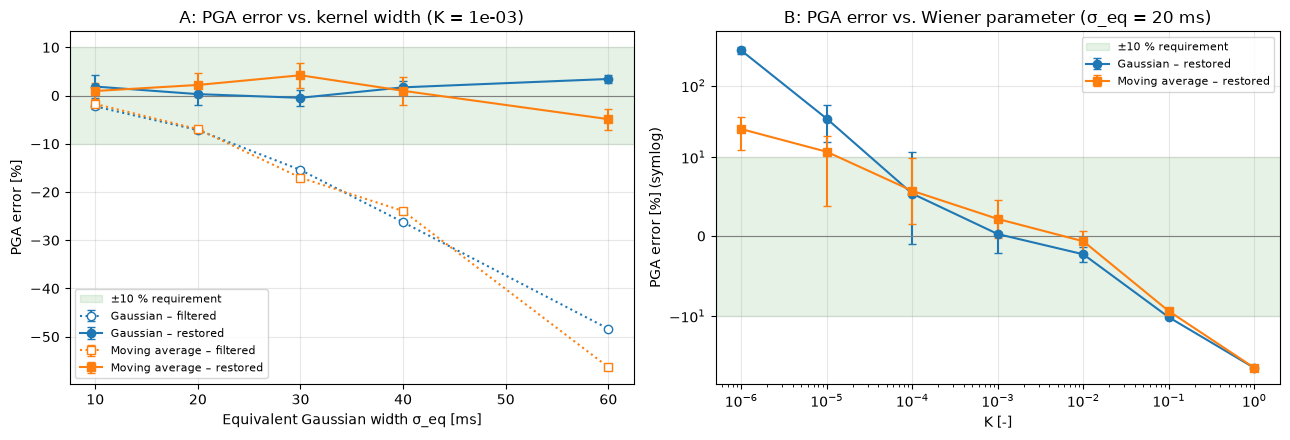

In [24]:
COLORS = {"Gaussian": "tab:blue", "Moving average": "tab:orange"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for kind, marker in [("Gaussian", "o"), ("Moving average", "s")]:
    c = COLORS[kind]
    d = df_width[df_width["Kernel"] == kind]
    axes[0].errorbar(d["Width σ_eq [ms]"], d["Filtered: mean [%]"], yerr=d["Filtered: std [%]"],
                     color=c, marker=marker, ls=":", mfc="white", capsize=3, label=f"{kind} – filtered")
    axes[0].errorbar(d["Width σ_eq [ms]"], d["Restored: mean [%]"], yerr=d["Restored: std [%]"],
                     color=c, marker=marker, ls="-", capsize=3, label=f"{kind} – restored")
    d = df_k[df_k["Kernel"] == kind]
    axes[1].errorbar(d["K"], d["Restored: mean [%]"], yerr=d["Restored: std [%]"],
                     color=c, marker=marker, capsize=3, label=f"{kind} – restored")

axes[1].set_xscale("log")
axes[1].set_yscale("symlog", linthresh=THRESHOLD_PCT)   # linear within ±10 %, logarithmic outside
axes[0].set(title=f"A: PGA error vs. kernel width (K = {BASELINE_K:.0e})",
            xlabel="Equivalent Gaussian width σ_eq [ms]", ylabel="PGA error [%]")
axes[1].set(title=f"B: PGA error vs. Wiener parameter (σ_eq = {BASELINE_SIGMA_S*1000:.0f} ms)",
            xlabel="K [-]", ylabel="PGA error [%] (symlog)")
for ax in axes:
    ax.axhspan(-THRESHOLD_PCT, THRESHOLD_PCT, color="green", alpha=0.1,
               label=f"±{THRESHOLD_PCT} % requirement")
    ax.axhline(0, color="gray", lw=0.8)
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Results.** Relative to the original PGA of 104.8 gal (inner segment), the baseline (Gaussian, σ = 20 ms, $K = 10^{-3}$) gives a PGA error of −7.15 ± 0.54 % for the filtered signal and +0.30 ± 2.32 % for the restored signal.

- *Kernel width (A):* the PGA error of the filtered signal grows from −2.25 % (σ = 10 ms) to −48.36 % (σ = 60 ms) for the Gaussian, and from −1.73 % to −56.31 % for the moving average. After restoration, the error stays within ±10 % for all widths: −0.46 to +3.44 % (Gaussian) and −4.89 to +4.22 % (moving average). The standard deviation of the restored Gaussian error decreases from 2.46 % to 0.84 %, while that of the moving average lies between 1.58 % and 2.93 %.
- *Wiener parameter (B):* for $K \le 10^{-5}$, the restored PGA error is positive and exceeds +10 %: +309.06 ± 32.58 % (Gaussian) and +24.60 ± 11.97 % (moving average) at $K = 10^{-6}$. For $K \ge 10^{-1}$, the error is negative (−53.47 % and −53.26 % at $K = 1$) with a standard deviation below 0.5 %. The requirement of ±10 % is met for $K = 10^{-4}$ to $10^{-2}$ (Gaussian) and $K = 10^{-4}$ to $10^{-1}$ (moving average). At $K = 10^{-4}$, the Gaussian mean error (+5.39 %) is within the requirement, but its standard deviation (6.34 %) is the largest within this range.

## Day 15 – Analysis & Communication, Final Reflection & Revisions

### Key Results (from Day 13 and Day 14)

| Configuration | Filtered PGA error | Restored PGA error | Requirement ±10 % |
|---|---|---|---|
| **Baseline:** Gaussian σ = 20 ms, $K = 10^{-3}$ | −7.15 ± 0.54 % | +0.30 ± 2.32 % | met |
| Moving average L = 7, $K = 10^{-3}$ | −6.96 ± 0.40 % | +2.20 ± 2.41 % | met |
| Gaussian σ = 60 ms, $K = 10^{-3}$ | −48.36 ± 0.24 % | +3.44 ± 0.84 % | met after restoration |
| Moving average L = 21, $K = 10^{-3}$ | −56.31 ± 0.18 % | −4.89 ± 2.15 % | met after restoration |
| Gaussian σ = 20 ms, $K = 10^{-6}$ | −7.15 ± 0.54 % | +309.06 ± 32.58 % | not met (noise amplification) |
| Gaussian σ = 20 ms, $K = 1$ | −7.15 ± 0.54 % | −53.47 ± 0.09 % | not met (residual smoothing) |
| Gaussian σ = 20 ms, $K = 0$ (naive inverse, Day 13) | – | max. 6.81·10³ gal | not met (unstable) |

All values: signed relative PGA error with respect to the original PGA of 104.8 gal, mean ± standard deviation over 20 noise realizations at 30 dB SNR.

### Analysis

**Observations.** At baseline, smoothing lowered the PGA by 7.15 %, and Wiener deconvolution restored it to +0.30 ± 2.32 %. The smoothing loss grew with kernel width to −48 % (Gaussian) and −56 % (moving average) at 60 ms, yet the restored error stayed within ±10 % for all widths. Varying $K$ revealed a clear trade-off: $K \le 10^{-5}$ amplified noise (+309 % for the Gaussian), $K = 1$ left the smoothing in place (−53 %), and naive inversion was unstable (6.8·10³ gal).

**Interpretation.** Convolution achieved its purpose: σ = 20 ms suppressed high-frequency fluctuations while keeping the PGA within the requirement, whereas widths of 30 ms or more did not (−15 % and beyond). Deconvolution was meaningful even after about half of the PGA had been lost, provided $K$ lay between $10^{-4}$ and $10^{-2}$. The SNR-based choice $K = 10^{-3}$ was therefore close to optimal.

**Discussion.** Contrary to the plan, the moving average was restored as accurately as the Gaussian (at most 4.9 % error). Its spectral zeros mostly affect frequencies where the signal carries little energy and noise dominates, while the PGA is driven by the 2–4 Hz S-wave pulses. These results assume an exactly known kernel and white noise of known level; in practice, both must be estimated, and the PGA alone does not capture onset or waveform fidelity.

### Personal Reflection

What impressed me most was how much a regularized deconvolution can recover: a PGA almost halved by Gaussian smoothing (−48 %) returned to +3.4 %. The most insightful result, however, was where it failed. I considered the Gaussian the "safe" kernel because its response has no zeros, yet it diverged far more at small $K$ than the moving average (+309 % vs. +25 %). In theory, a response without zeros is invertible; in practice, values far below the noise level act like zeros. The other blocks showed the same gap: the sampling theorem assumes strict band-limitation, while the record only concentrates 99 % of its energy below 11.2 Hz, and the NCC detection margin unexpectedly increased with moderate noise because noise masked competing coda peaks. If I repeated the challenge, I would use a real system response, such as a KiK-net borehole–surface pair, and add a waveform-based metric alongside the PGA.